# Threshold Exploration for over-integration analyses

## Library Imports

In [1]:
import warnings
import sys 
import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# import scipy
# import json

import scanpy as sc
import statsmodels.stats.multitest as mtc

# Set path
notebooks_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
atlas_extension_dir = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
sys.path.append(atlas_extension_dir)

from mapqc.MapAnalyzer import AdataHandler, MappingScoring

## General settings

In [2]:
# Set global seed
np.random.seed(42)

# Ignore warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

# Set directories
DATA_DIR = os.path.abspath(os.path.join(atlas_extension_dir, "data"))

#os.makedirs(os.path.join(notebooks_dir, 'scores_highres'), exist_ok=True)
#SCORES_DIR = os.path.abspath(os.path.join(notebooks_dir, "scores_highres"))

os.makedirs(os.path.join(notebooks_dir, 'Overintegration highres results'), exist_ok=True)
RESULTS_DIR = os.path.abspath(os.path.join(notebooks_dir, "Overintegration highres results"))

os.makedirs(os.path.join(RESULTS_DIR, "figures"), exist_ok=True)
FIG_DIR = os.path.abspath(os.path.join(RESULTS_DIR, "figures"))

# Plot settings
sns.set(rc={"figure.figsize": (12, 7)})

## Function definitions

In [3]:
def filter_query_conditions(
    query_conditions,
    selected_conditions,
):
    return {
        dataset: [
            [condition_label] if not isinstance(condition_label, list) else condition_label, 
            [excluded_cond for excluded_cond in query_conditions[dataset] 
                if excluded_cond != condition_label and 'healthy' not in excluded_cond.lower()]
            ] 
        for condition_label, dataset in zip(selected_conditions, query_conditions.keys())
    }

In [164]:
def get_rejection_table(
    aggregated_query, 
    scorer_dict, 
    sample_condition, 
    query_dataset_id,
    cutoff_pval = 0.05, 
    n_ct_threshold = 0, 
    return_pvalues = False
):
    
    query_summary = pd.DataFrame(
        columns = ["Dataset", "Sample_condition", "N_rejected", "N_all", "Fraction", "Accepted disease"]
    )
    cell_types_pvals = {}
    for query_dataset in aggregated_query.keys():
        pvals = []
        for ct in aggregated_query[query_dataset].cell_label.cat.categories:

            scores_query = aggregated_query[query_dataset][
                (aggregated_query[query_dataset].dataset == query_dataset_id)
                & (aggregated_query[query_dataset].disease_or_healthy == sample_condition)
                & (aggregated_query[query_dataset].cell_label == ct)
            ].score

            scores_reference = aggregated_query[query_dataset][
                ~(aggregated_query[query_dataset].dataset == query_dataset_id) 
                & (aggregated_query[query_dataset].cell_label == ct)
            ].score

            if len(scores_query) >= 3:
                ks_pval = scorer_dict[query_dataset].perform_one_sided_ks_test(scores_query, scores_reference)
                pvals.append((ct, ks_pval))

        if len(pvals) < 1:
            continue

        tested_cell_types = pd.DataFrame(data=pvals, columns=["cell_label", "pvalue"])
        tested_cell_types["pvals_corr"] = mtc.multipletests(
            tested_cell_types["pvalue"], 
            cutoff_pval, 
            "fdr_bh"
        )[1]

        tested_cell_types["Significant"] = tested_cell_types["pvals_corr"] < cutoff_pval
        cell_types_pvals[query_dataset] = tested_cell_types
        rejected = tested_cell_types[tested_cell_types.pvals_corr < cutoff_pval]

        summary = {
            "Dataset": query_dataset, 
            "Sample_condition": sample_condition, 
            "N_rejected": len(rejected), 
            "N_all": len(tested_cell_types), 
            "Fraction": len(rejected) / len(tested_cell_types), 
            "Accepted disease": len(rejected) > n_ct_threshold
        }

        query_summary = pd.concat(
            [query_summary, pd.DataFrame([summary])], 
            ignore_index=True
        )

    if len(query_summary) < 1:
        return None, None
    return (query_summary, cell_types_pvals) if return_pvalues else query_summary


In [179]:
def plot_score_distribution(
        aggregated_query, 
        query_dataset_id, 
        selected_conditions,
        title,
        save=False,
        filepath=None,
    ):   
    sns.violinplot(data=aggregated_query, x="cell_label", y="score", color="gray")
    sns.stripplot(
        data=aggregated_query[aggregated_query.dataset == query_dataset_id],
        x="cell_label",
        y="score",
        hue=aggregated_query.disease_or_healthy
    )
    
    # Legend
    legend = plt.gca().get_legend()
    legend.set_title("Disease status")
    legend.texts[0].set_text("Healthy")
    legend.texts[1].set_text(selected_conditions)

    plt.title(f"Ref vs. {title}", fontsize=20)
    plt.xticks(rotation=90)

    if save and filepath:
        plt.savefig(filepath)

    plt.show()

## Data loading 

Load atlas

In [6]:
adata = sc.read(f"{DATA_DIR}/HLCA_full_v1.1_emb.h5ad")
adata

AnnData object with n_obs × n_vars = 2282447 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'ti

## Q2R mapping evaluation via MapQC

Select query datasets

In [7]:
query_ids = ['Sheppard_2020', 'Lafyatis_2019']

query_handlers = {}
query_conditions = {}
scorer = {}

# Augment cell type resolution
paga_thresholds = [2]
min_subjects = [25, 20]

Initialize AnnData handlers

In [8]:
for query_dataset in query_ids:   
    for theta in paga_thresholds:
        for min_sub in min_subjects:
            adata_handler = AdataHandler(
                adata = adata[
                    (adata.obs.core_or_extension == "core") 
                    | ((adata.obs.dataset == query_dataset))
                ].copy(),
                workspace = RESULTS_DIR,
                ident = f"{query_dataset} - t = {theta} - min_sub = {min_sub}" + "/",
                log = True,
            )
            query_handlers[f"{query_dataset} - t = {theta} - min_sub = {min_sub}"] = adata_handler

    lung_conditions = adata[adata.obs.dataset == query_dataset].obs.lung_condition.cat.categories.to_list()
    query_conditions[f"{query_dataset}"] = lung_conditions

Logger directory already exists
Logger directory already exists
Logger directory already exists
Logger directory already exists


In [9]:
query_handlers

{'Sheppard_2020 - t = 2 - min_sub = 25': <mapqc.MapAnalyzer.AdataHandler at 0x17aaf82b0>,
 'Sheppard_2020 - t = 2 - min_sub = 20': <mapqc.MapAnalyzer.AdataHandler at 0x14b309610>,
 'Lafyatis_2019 - t = 2 - min_sub = 25': <mapqc.MapAnalyzer.AdataHandler at 0x10422e8e0>,
 'Lafyatis_2019 - t = 2 - min_sub = 20': <mapqc.MapAnalyzer.AdataHandler at 0x104255040>}

In [10]:
for dataset in query_conditions.keys():
    print(dataset, query_conditions[dataset])

Sheppard_2020 ['Healthy', 'IPF', 'Systemic sclerosis-associated ILD']
Lafyatis_2019 ['Systemic sclerosis-associated ILD']


Select disease conditions

In [11]:
selected_conditions = ['IPF', 'Systemic sclerosis-associated ILD']
selected_query_conditions = filter_query_conditions(query_conditions, selected_conditions)
selected_query_conditions

{'Sheppard_2020': [['IPF'], ['Systemic sclerosis-associated ILD']],
 'Lafyatis_2019': [['Systemic sclerosis-associated ILD'], []]}

Standardize columns

In [12]:
for query_dataset in query_ids: 
    for theta in paga_thresholds:  
        for min_sub in min_subjects:
            query_handlers[
                f"{query_dataset} - t = {theta} - min_sub = {min_sub}"
            ].standarize_columns(
                condition_name=selected_query_conditions[f"{query_dataset}"][0], 
                query_dataset=query_dataset,
                cell_type_col=None,
                dataset_col="dataset",
                sample_col="sample",
                condition_col="lung_condition",
                subject_col="donor_id",
                disease_exclude=selected_query_conditions[f"{query_dataset}"][1],
            )

2023-07-20 13:58:18.055848	Standarizing columns...
2023-07-20 13:58:21.486349	No cell_type column set. Please make sure to run 'set_cell_type_levels' to obtain a unified cell type column 'cell_label'.
2023-07-20 13:58:21.490589	Finished column standarizing

2023-07-20 13:58:21.490692	Standarizing columns...
2023-07-20 13:58:25.437703	No cell_type column set. Please make sure to run 'set_cell_type_levels' to obtain a unified cell type column 'cell_label'.
2023-07-20 13:58:25.439146	Finished column standarizing

2023-07-20 13:58:25.439196	Standarizing columns...
2023-07-20 13:58:28.757837	No cell_type column set. Please make sure to run 'set_cell_type_levels' to obtain a unified cell type column 'cell_label'.
2023-07-20 13:58:28.759318	Finished column standarizing

2023-07-20 13:58:28.764771	Standarizing columns...
2023-07-20 13:58:32.370297	No cell_type column set. Please make sure to run 'set_cell_type_levels' to obtain a unified cell type column 'cell_label'.
2023-07-20 13:58:32.37110

Set cell type levels

In [13]:
for query_dataset in query_ids:
    for theta in paga_thresholds:
        for min_sub in min_subjects:
            query_handlers[
                f"{query_dataset} - t = {theta} - min_sub = {min_sub}"
            ].set_cell_type_levels(
                connect_threshold = theta, 
                annotation_columns = [f"ann_level_{i}" for i in range(1, 6)],
                finest_level_column = "ann_finest_level",
                unlabeled_tag = "nan")

2023-07-20 13:58:36.334108	starting with cell labels:
['AT0', 'AT1', 'AT2', 'AT2 proliferating', 'Adventitial fibroblasts', 'Alveolar Mph CCL3+', 'Alveolar Mph MT-positive', 'Alveolar Mph proliferating', 'Alveolar fibroblasts', 'Alveolar macrophages', 'B cells', 'Basal resting', 'CD4 T cells', 'CD8 T cells', 'Classical monocytes', 'Club (nasal)', 'Club (non-nasal)', 'DC1', 'DC2', 'Deuterosomal', 'EC aerocyte capillary', 'EC arterial', 'EC general capillary', 'EC venous pulmonary', 'EC venous systemic', 'Goblet (bronchial)', 'Goblet (nasal)', 'Goblet (subsegmental)', 'Hematopoietic stem cells', 'Hillock-like', 'Interstitial Mph perivascular', 'Ionocyte', 'Lymphatic EC differentiating', 'Lymphatic EC mature', 'Lymphatic EC proliferating', 'Mast cells', 'Mesothelium', 'Migratory DCs', 'Monocyte-derived Mph', 'Multiciliated (nasal)', 'Multiciliated (non-nasal)', 'Myofibroblasts', 'NK cells', 'Neuroendocrine', 'Non-classical monocytes', 'Peribronchial fibroblasts', 'Pericytes', 'Plasma cell

Transfer labels

In [14]:
for query_dataset in query_ids:
    for theta in paga_thresholds:
        for min_sub in min_subjects:
            query_handlers[
                f"{query_dataset} - t = {theta} - min_sub = {min_sub}"
            ].transfer_labels(
                transfer_columns=["cell_label"], 
                pickle=False
            )

2023-07-20 14:05:37.432179	Transferring labels...
2023-07-20 14:05:38.386581	Train KNNModel
Weighted KNN with n_neighbors = 50 ... 2023-07-20 14:05:38.711888	transferring cell_label
finished!
2023-07-20 14:06:11.311915	Transferring labels...
2023-07-20 14:06:12.386638	Train KNNModel
Weighted KNN with n_neighbors = 50 ... 2023-07-20 14:06:12.952753	transferring cell_label
finished!
2023-07-20 14:06:47.511415	Transferring labels...
2023-07-20 14:06:48.503720	Train KNNModel
Weighted KNN with n_neighbors = 50 ... 2023-07-20 14:06:48.930418	transferring cell_label
finished!
2023-07-20 14:07:06.103304	Transferring labels...
2023-07-20 14:07:07.002029	Train KNNModel
Weighted KNN with n_neighbors = 50 ... 2023-07-20 14:07:07.260449	transferring cell_label
finished!


Compute query and baseline mixing scores

In [18]:
for query_dataset in query_ids: 
    print(f"Dataset: {query_dataset} \n")
    for theta in paga_thresholds:
        print(f"Theta = {theta} \n")
        for min_sub in min_subjects:
            print(f"Min. subjects = {min_sub} \n")

            # Instantiate scorer
            scorer[f"{query_dataset} - t = {theta} - min_sub = {min_sub}"] = (
                MappingScoring(query_handlers[f"{query_dataset} - t = {theta} - min_sub = {min_sub}"])
            )

            # Set scores paths
            query_scores_path = os.path.join(
                RESULTS_DIR, 
                f"{query_dataset} - t = {theta} - min_sub = {min_sub}", 
                f"scores_{selected_query_conditions[query_dataset][0][0]}.csv"
            )
            baseline_path = os.path.join(
                RESULTS_DIR, f"t = {theta} - min_sub = {min_sub}", "baseline.csv"
            )
            cell_labels_path = os.path.join(
                RESULTS_DIR, f"t = {theta} - min_sub = {min_sub}", "cell_types.txt"
            )

            if os.path.exists(query_scores_path):
                # Add mixing scores from disc
                scorer[f"{query_dataset} - t = {theta} - min_sub = {min_sub}"].add_scores(query_scores_path)
            else:
                # Compute mixing scores
                scorer[f"{query_dataset} - t = {theta} - min_sub = {min_sub}"].calculate_mixing_scores(
                    adata = query_handlers[f"{query_dataset} - t = {theta} - min_sub = {min_sub}"].get_adata(),
                    #reinitialize = False,
                    min_subjects = min_sub,
                    verbose = False,
                    save = query_scores_path,
                )

            if os.path.exists(baseline_path):
                # Add baseline from disc
                scorer[f"{query_dataset} - t = {theta} - min_sub = {min_sub}"].add_baseline_simplified(
                    baseline_path = baseline_path,
                    cell_label_path = cell_labels_path,
                )
            else:
                # Compute baseline scores
                scorer[f"{query_dataset} - t = {theta} - min_sub = {min_sub}"].calculate_baseline(
                    min_subjects = min_sub,
                    verbose = False,
                    save = os.path.join(RESULTS_DIR, f"t = {theta} - min_sub = {min_sub}")
                )

Dataset: Sheppard_2020 

Theta = 2 

Min. subjects = 25 

Logger directory already exists
2023-07-20 14:12:36.106298	Baseline consists of following cell types:

2023-07-20 14:12:36.107461	AT1


2023-07-20 14:12:36.107487	AT2


2023-07-20 14:12:36.107497	Adventitial fibroblasts


2023-07-20 14:12:36.107507	Alveolar fibroblasts


2023-07-20 14:12:36.107515	Alveolar macrophages


2023-07-20 14:12:36.107523	B cells


2023-07-20 14:12:36.107531	Basal resting


2023-07-20 14:12:36.107539	CD4 T cells


2023-07-20 14:12:36.107547	CD8 T cells


2023-07-20 14:12:36.107555	Classical monocytes


2023-07-20 14:12:36.107563	Club (nasal)


2023-07-20 14:12:36.107571	Club (non-nasal)


2023-07-20 14:12:36.107579	DC2


2023-07-20 14:12:36.107586	EC aerocyte capillary


2023-07-20 14:12:36.107593	EC arterial


2023-07-20 14:12:36.107601	EC general capillary


2023-07-20 14:12:36.107608	EC venous pulmonary


2023-07-20 14:12:36.107616	EC venous systemic


2023-07-20 14:12:36.107623	Goblet (nasal)


2023-

100%|██████████| 55/55 [00:22<00:00,  2.41it/s]


Dataset: Lafyatis_2019 

Theta = 2 

Min. subjects = 25 

Logger directory already exists


100%|██████████| 55/55 [03:30<00:00,  3.84s/it]


2023-07-20 14:57:24.396928	Baseline consists of following cell types:

2023-07-20 14:57:24.397505	AT1


2023-07-20 14:57:24.397520	AT2


2023-07-20 14:57:24.397530	Adventitial fibroblasts


2023-07-20 14:57:24.397538	Alveolar fibroblasts


2023-07-20 14:57:24.397545	Alveolar macrophages


2023-07-20 14:57:24.397553	B cells


2023-07-20 14:57:24.397560	Basal resting


2023-07-20 14:57:24.397567	CD4 T cells


2023-07-20 14:57:24.397574	CD8 T cells


2023-07-20 14:57:24.397581	Classical monocytes


2023-07-20 14:57:24.397588	Club (nasal)


2023-07-20 14:57:24.397595	Club (non-nasal)


2023-07-20 14:57:24.397602	DC2


2023-07-20 14:57:24.397609	EC aerocyte capillary


2023-07-20 14:57:24.397616	EC arterial


2023-07-20 14:57:24.397623	EC general capillary


2023-07-20 14:57:24.397630	EC venous pulmonary


2023-07-20 14:57:24.397638	EC venous systemic


2023-07-20 14:57:24.397645	Goblet (nasal)


2023-07-20 14:57:24.397652	Interstitial Mph perivascular


2023-07-20 14:57:24.397659	Lymphatic

100%|██████████| 55/55 [03:00<00:00,  3.29s/it]


2023-07-20 15:00:26.320180	Baseline consists of following cell types:

2023-07-20 15:00:26.320745	AT1


2023-07-20 15:00:26.320893	AT2


2023-07-20 15:00:26.320903	Adventitial fibroblasts


2023-07-20 15:00:26.320911	Alveolar fibroblasts


2023-07-20 15:00:26.320918	Alveolar macrophages


2023-07-20 15:00:26.320925	B cells


2023-07-20 15:00:26.320931	Basal resting


2023-07-20 15:00:26.320937	CD4 T cells


2023-07-20 15:00:26.320943	CD8 T cells


2023-07-20 15:00:26.320949	Classical monocytes


2023-07-20 15:00:26.320956	Club (nasal)


2023-07-20 15:00:26.320962	Club (non-nasal)


2023-07-20 15:00:26.320968	DC2


2023-07-20 15:00:26.320974	Deuterosomal


2023-07-20 15:00:26.320980	EC aerocyte capillary


2023-07-20 15:00:26.320986	EC arterial


2023-07-20 15:00:26.320992	EC general capillary


2023-07-20 15:00:26.320998	EC venous pulmonary


2023-07-20 15:00:26.321004	EC venous systemic


2023-07-20 15:00:26.321009	Goblet (nasal)


2023-07-20 15:00:26.321016	Hillock-like


2023-07-20 

Add log-linear model fit from reference samples

In [19]:
for query_dataset in query_ids: 
    for theta in paga_thresholds:
        for min_sub in min_subjects:
            # Correct raw scores for sample size

            # Compute from scratch (only once suffices)
            scorer[f"{query_dataset} - t = {theta} - min_sub = {min_sub}"].calculate_transformation(
                save = False
            ) 

            # Add from disc
            #scorer[query_dataset].add_transformation(
            #    transformation_path = os.path.join(RESULTS_DIR, 'transformation.csv')
            #)

Transform query scores

In [20]:
aggregated_query = {}

In [21]:
for query_dataset in query_ids: 
    for theta in paga_thresholds:
        for min_sub in min_subjects:
            aggregated_query[f"{query_dataset} - t = {theta} - min_sub = {min_sub}"] = (
                scorer[
                    f"{query_dataset} - t = {theta} - min_sub = {min_sub}"
                ].apply_transformation(scorer[
                    f"{query_dataset} - t = {theta} - min_sub = {min_sub}"
                    ].get_adata())
            )

2023-07-20 15:07:43.701805	Correcting for sample size...
2023-07-20 15:07:43.916649	Correcting for sample size...
2023-07-20 15:07:44.113901	Correcting for sample size...
2023-07-20 15:07:44.314614	Correcting for sample size...


Evaluate query dataset acceptance

In [165]:
rejection_tables = []
pvals_tables = []

In [166]:
for query_dataset_id in query_ids:    
    for sample_condition in ["healthy", "disease"]:
        rejection_tab, pvals_tab = get_rejection_table(
            aggregated_query, 
            scorer, 
            query_dataset_id=query_dataset_id,
            sample_condition=sample_condition,
            return_pvalues=True
        )
        if rejection_tab is not None:
            rejection_tables.append(rejection_tab)  
        if pvals_tab is not None:
            pvals_tables.append(pvals_tab)

In [167]:
rejection_tables

[                                Dataset Sample_condition N_rejected N_all   
 0  Sheppard_2020 - t = 2 - min_sub = 25          healthy          0    17  \
 1  Sheppard_2020 - t = 2 - min_sub = 20          healthy          0    18   
 
    Fraction Accepted disease  
 0       0.0            False  
 1       0.0            False  ,
                                 Dataset Sample_condition N_rejected N_all   
 0  Sheppard_2020 - t = 2 - min_sub = 25          disease          0     6  \
 1  Sheppard_2020 - t = 2 - min_sub = 20          disease          0     7   
 
    Fraction Accepted disease  
 0       0.0            False  
 1       0.0            False  ,
                                 Dataset Sample_condition N_rejected N_all   
 0  Lafyatis_2019 - t = 2 - min_sub = 25          disease          0    28  \
 1  Lafyatis_2019 - t = 2 - min_sub = 20          disease          0    29   
 
    Fraction Accepted disease  
 0       0.0            False  
 1       0.0            False  ]

In [169]:
pvals_tables

[{'Sheppard_2020 - t = 2 - min_sub = 25':                        cell_label    pvalue  pvals_corr  Significant
  0                             AT1  0.561328    1.000000        False
  1                             AT2  0.953596    1.000000        False
  2         Adventitial fibroblasts  0.632112    1.000000        False
  3            Alveolar fibroblasts  1.000000    1.000000        False
  4            Alveolar macrophages  0.894615    1.000000        False
  5             Classical monocytes  0.814227    1.000000        False
  6                             DC2  0.778099    1.000000        False
  7           EC aerocyte capillary  0.769704    1.000000        False
  8                     EC arterial  0.956878    1.000000        False
  9            EC general capillary  0.792975    1.000000        False
  10            EC venous pulmonary  0.852101    1.000000        False
  11             EC venous systemic  0.982759    1.000000        False
  12  Interstitial Mph perivascular  

Plot mixing scores

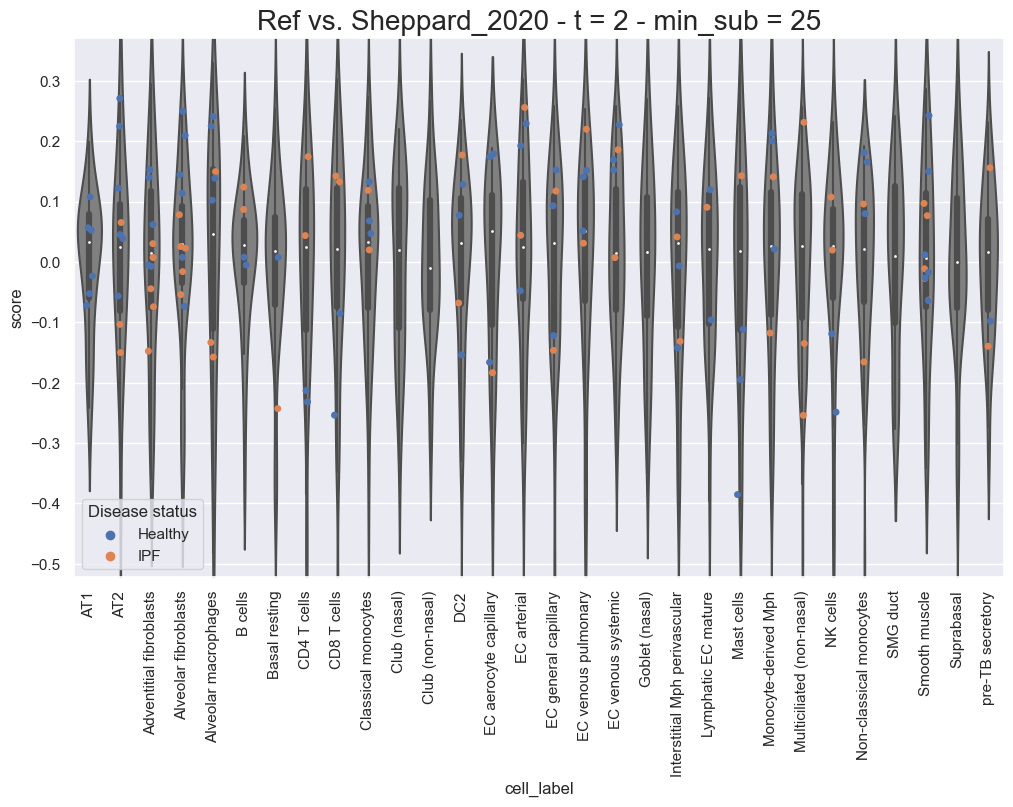

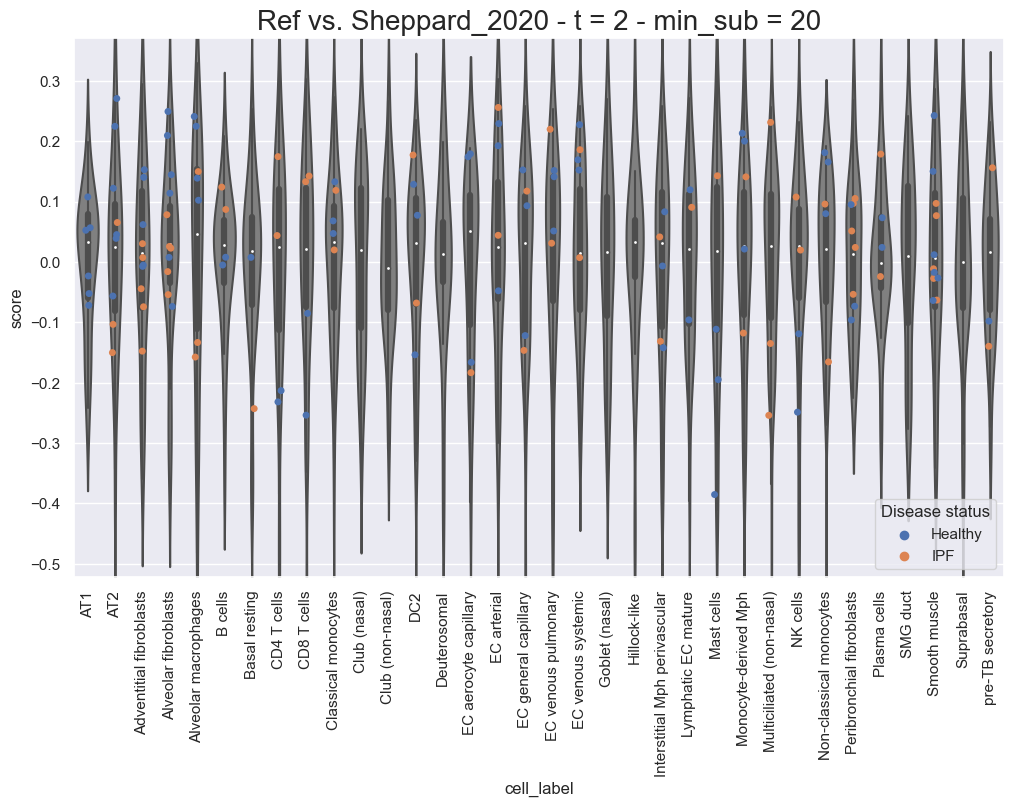

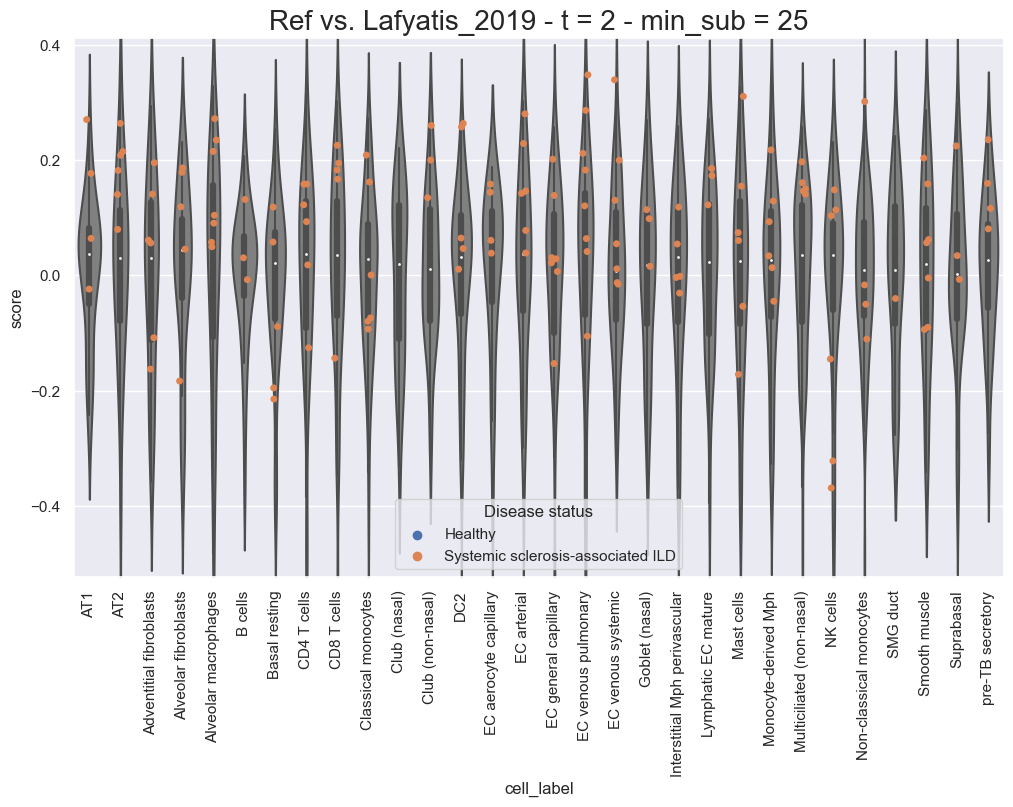

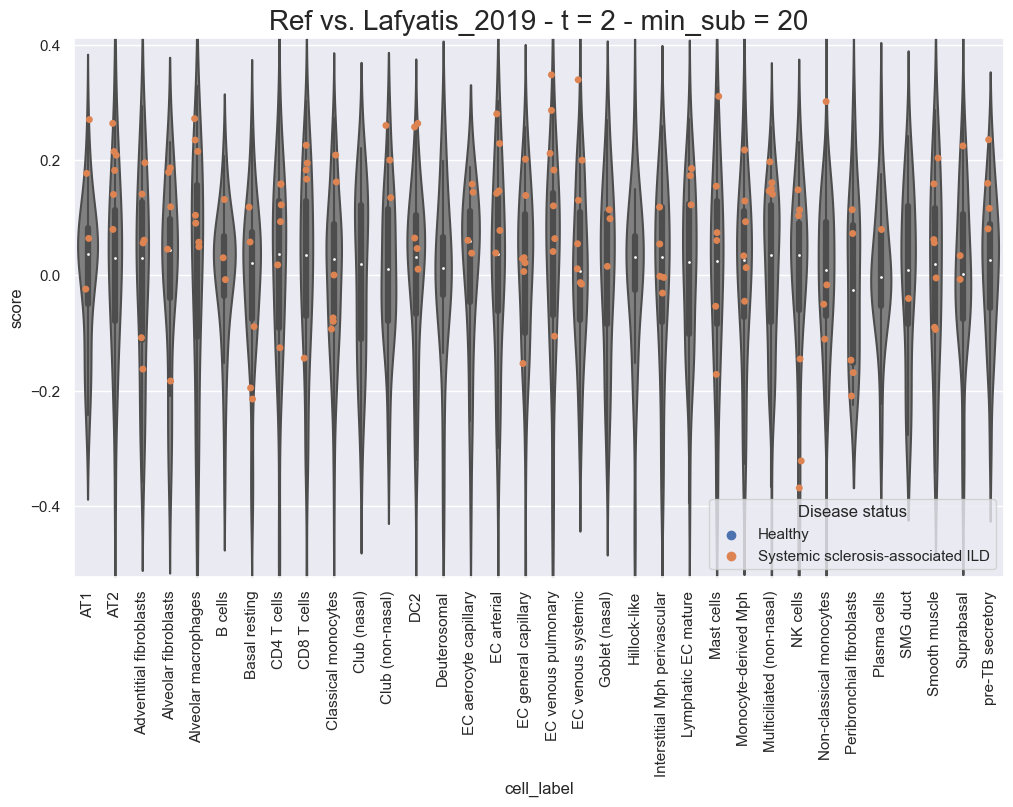

In [182]:
for query_dataset in aggregated_query.keys():     
    plot_score_distribution(
        aggregated_query[query_dataset], 
        query_dataset_id=query_dataset.split(" - ")[0], 
        selected_conditions=selected_query_conditions[query_dataset.split(" - ")[0]][0][0],
        title=query_dataset,
        save=True,
        filepath=os.path.join(FIG_DIR, f"{query_dataset}")
    )